# SCA Homework 1 – Forecasting Airline Passengers
Parts I–III.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import itertools
import warnings
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
warnings.filterwarnings("ignore")

In [2]:
# load data
df = pd.read_csv("data/Homework1_TSA130.csv")
df = df.dropna()
df["Date"] = pd.to_datetime(df["Date"], format="%b-%y")

y = df.set_index("Date")["Number of Passengers (x1000)"]
y = y.asfreq("MS")

print(len(y), "months, missing values:", y.isna().sum())
y.head()

130 months, missing values: 0


Date
2014-01-01    113.0
2014-02-01    119.0
2014-03-01    139.0
2014-04-01    129.0
2014-05-01    124.0
Freq: MS, Name: Number of Passengers (x1000), dtype: float64

## I. Visualisation

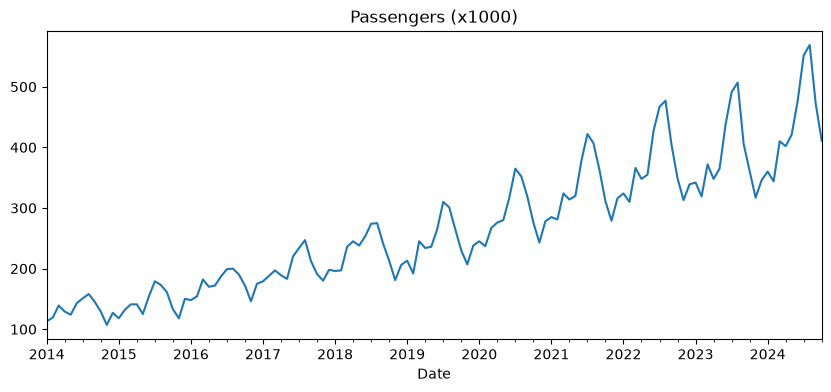

In [3]:
# time series
y.plot(figsize=(10, 4), title="Passengers (x1000)")
plt.show()

Plotting one line per year

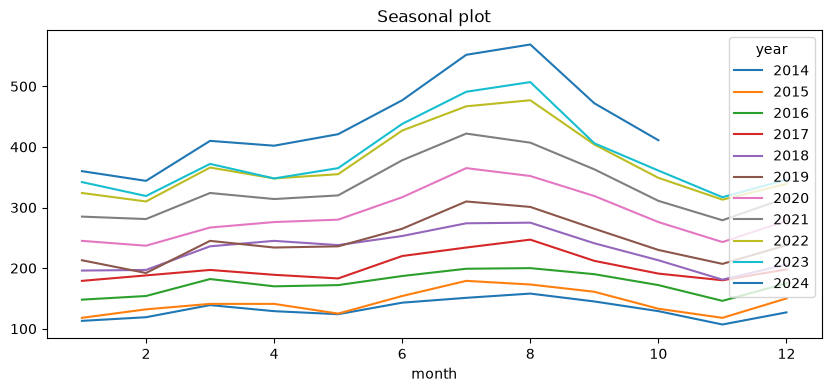

In [4]:

df["year"] = df["Date"].dt.year
df["month"] = df["Date"].dt.month
table = df.pivot(index="month", columns="year", values="Number of Passengers (x1000)")
table.plot(figsize=(10, 4), title="Seasonal plot")
plt.show()

Total per year

In [5]:
y.groupby(y.index.year).sum()

Date
2014    1584.0
2015    1725.0
2016    2095.0
2017    2418.0
2018    2755.0
2019    2936.0
2020    3455.0
2021    4000.0
2022    4479.0
2023    4612.0
2024    4418.0
Name: Number of Passengers (x1000), dtype: float64

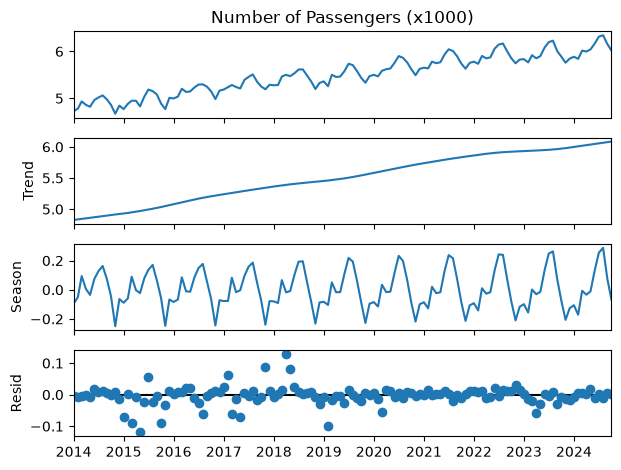

Date
2015-05-01   -3.832415
2017-11-01    3.017498
2018-04-01    4.326006
2019-02-01   -3.119425
Name: resid, dtype: float64

In [6]:
# decomposition of log(y) into trend, season and residual
stl = STL(np.log(y), period=12, robust=True).fit()
stl.plot()
plt.show()

#Months with a large residual
resid = stl.resid
z = (resid - resid.mean()) / resid.std()
z[abs(z) > 3]

- 130 months (Jan-14 to Oct-24), 2024 runs only to October.
- A few STL residuals stand out (May-15, Apr-18), but they are small in absolute terms.
- Clear upward trend (flattening in 2023–24) and yearly seasonality, with a peak in Jul – Aug.
- Seasonal swings grow with the level -> multiplicative, so we model log(y).

## II. Stationarity
ADF test: H₀ = unit root (non-stationary), so p < 0.05 means stationary.

In [7]:
ly = np.log(y)
for name, x in [("log y", ly), ("first difference", ly.diff()),
                ("seasonal difference", ly.diff(12)), ("both differences", ly.diff().diff(12))]:
    print(name, " ADF p =", round(adfuller(x.dropna())[1], 3))

log y  ADF p = 0.638
first difference  ADF p = 0.017
seasonal difference  ADF p = 0.067
both differences  ADF p = 0.004


- log y: ADF p = 0.64, so non-stationary.
- First difference: ADF p = 0.017, but the seasonal pattern is still there, so a seasonal difference is also needed.
- Both differences: ADF p = 0.004, so stationary. Use d = 1, D = 1.

## III. Models
Last 12 months are the test set (for part IV).

In [8]:
train = y[:-12]
test_set = y[-12:]

### (a) Exponential smoothing (Holt-Winters)
Try all trend/seasonal options, pick the lowest AIC.

In [9]:
results = []
for trend in ["additive", "multiplicative"]:
    for damped in [False, True]:
        for seasonal in ["additive", "multiplicative"]:
            m = ExponentialSmoothing(train, trend=trend, damped_trend=damped,
                                     seasonal=seasonal, seasonal_periods=12).fit()
            results.append([trend, damped, seasonal, m.aic])

results = pd.DataFrame(results, columns=["trend", "damped", "seasonal", "AIC"])
results.sort_values("AIC")

,trend,damped,seasonal,AIC
1,additive,False,multiplicative,590.976821
5,multiplicative,False,multiplicative,592.505797
7,multiplicative,True,multiplicative,592.515563
3,additive,True,multiplicative,597.001134
0,additive,False,additive,622.042682
4,multiplicative,False,additive,624.635732
6,multiplicative,True,additive,626.550232
2,additive,True,additive,627.737053


In [10]:
# best model
ets = ExponentialSmoothing(train, trend="additive", damped_trend=False,
                           seasonal="multiplicative", seasonal_periods=12).fit()
ets.params

{'smoothing_level': np.float64(0.28597767493333703),
 'smoothing_trend': np.float64(0.0),
 'smoothing_seasonal': np.float64(0.6498820855539171),
 'damping_trend': nan,
 'initial_level': np.float64(130.5591894326844),
 'initial_trend': np.float64(2.688377251560807),
 'initial_seasons': array([0.84698766, 0.88336001, 0.9918707 , 0.9186669 , 0.85119241,
        0.96989589, 1.02780292, 1.0424708 , 0.95693962, 0.84953217,
        0.73633848, 0.87780145]),
 'use_boxcox': False,
 'lamda': None,
 'remove_bias': False}

### (b) SARIMA on log y
d = 1, D = 1 from part II. Look at ACF/PACF, then try small models and pick the lowest AIC.

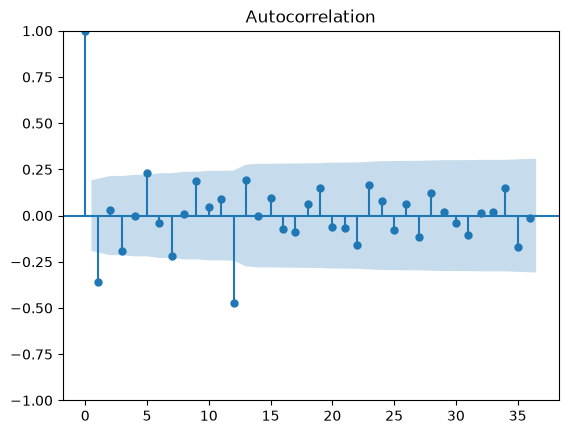

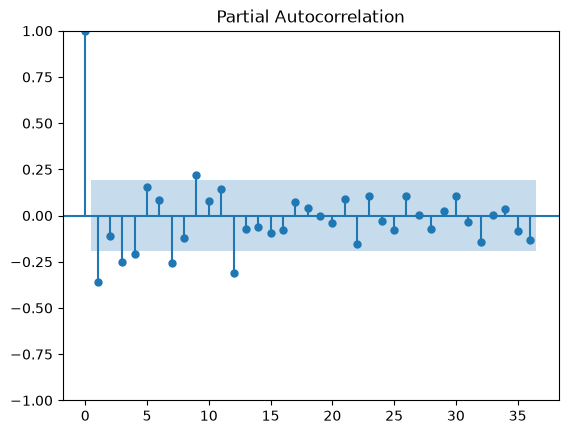

In [11]:
log_train = np.log(train)
x = log_train.diff().diff(12).dropna()

plot_acf(x, lags=36)
plot_pacf(x, lags=36)
plt.show()

ACF spikes at lag 1 and 12, so MA(1) and SMA(1).

In [12]:
results = []
for p, q, P, Q in itertools.product([0, 1, 2], [0, 1, 2], [0, 1], [0, 1]):
    m = SARIMAX(log_train, order=(p, 1, q), seasonal_order=(P, 1, Q, 12)).fit(disp=False)
    results.append([p, q, P, Q, m.aic])

results = pd.DataFrame(results, columns=["p", "q", "P", "Q", "AIC"])
results.sort_values("AIC").head()

,p,q,P,Q,AIC
5,0,1,0,1,-347.321952
7,0,1,1,1,-347.252557
6,0,1,1,0,-346.210417
17,1,1,0,1,-346.044587
9,0,2,0,1,-345.681917


In [13]:
# best model
sarima = SARIMAX(log_train, order=(0, 1, 1), seasonal_order=(0, 1, 1, 12)).fit(disp=False)
print(sarima.summary())

#res should be white noise with p > 0.05
acorr_ljungbox(sarima.resid[13:], lags=[12, 24])

                                     SARIMAX Results                                      
Dep. Variable:       Number of Passengers (x1000)   No. Observations:                  118
Model:             SARIMAX(0, 1, 1)x(0, 1, 1, 12)   Log Likelihood                 176.661
Date:                            Thu, 29 Oct 2026   AIC                           -347.322
Time:                                    16:39:53   BIC                           -339.360
Sample:                                01-01-2014   HQIC                          -344.096
                                     - 10-01-2023                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1         -0.4768      0.090     -5.313      0.000      -0.653      -0.301
ma.S.L12      -0.5809      0.114   

,lb_stat,lb_pvalue
12,12.719681,0.389740
24,23.106290,0.513531


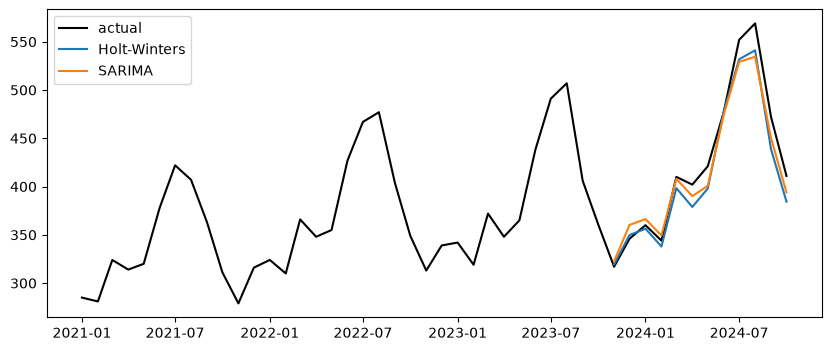

In [14]:
#Forecasts for the test year
fc_ets = ets.forecast(12)
fc_sarima = np.exp(sarima.forecast(12))

plt.figure(figsize=(10, 4))
plt.plot(y["2021":], color="black", label="actual")
plt.plot(fc_ets, label="Holt-Winters")
plt.plot(fc_sarima, label="SARIMA")
plt.legend()
plt.show()

- ETS: additive trend + multiplicative seasonality has the lowest AIC.
- SARIMA(0,1,1)(0,1,1)_12 on log y (the "airline model"); both MA terms are significant, Ljung-Box p > 0.05 so white-noise residuals.
- Both models follow the test year closely